<a href="https://colab.research.google.com/github/ngjingwen-0320/6001CMD_GroupProject/blob/main/online_shoppers_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [60]:
# Data manipulation
import os
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Reproducibility
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [61]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [62]:
PROJECT_DIR = "/content/drive/MyDrive/Online_Shoppers_ML"
DATA_DIR = os.path.join(PROJECT_DIR, "data")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(RESULTS_DIR, exist_ok=True)

df = pd.read_csv(
    os.path.join(DATA_DIR, "online_shoppers_intention_raw.csv")
)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully.
Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [63]:
# Check dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Check column names and data types
df.info()

Number of rows: 12330
Number of columns: 18
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 n

Revenue
False    10422
True      1908
Name: count, dtype: int64

Target distribution (%):
Revenue
False    84.53
True     15.47
Name: proportion, dtype: float64


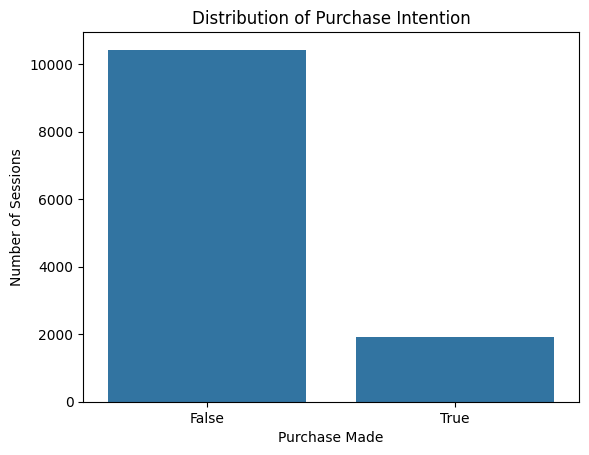

In [64]:
# Count purchase and non-purchase sessions
print(df["Revenue"].value_counts())

# Calculate percentages
print("\nTarget distribution (%):")
print((df["Revenue"].value_counts(normalize=True) * 100).round(2))

# Visualise the target distribution
sns.countplot(data=df, x="Revenue")
plt.title("Distribution of Purchase Intention")
plt.xlabel("Purchase Made")
plt.ylabel("Number of Sessions")
plt.show()

In [65]:
# Count missing values in each column
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage (%)": (missing_values / len(df) * 100).round(2)
})

print(missing_summary)

                         Missing Values  Missing Percentage (%)
Administrative                        0                     0.0
Administrative_Duration               0                     0.0
Informational                         0                     0.0
Informational_Duration                0                     0.0
ProductRelated                        0                     0.0
ProductRelated_Duration               0                     0.0
BounceRates                           0                     0.0
ExitRates                             0                     0.0
PageValues                            0                     0.0
SpecialDay                            0                     0.0
Month                                 0                     0.0
OperatingSystems                      0                     0.0
Browser                               0                     0.0
Region                                0                     0.0
TrafficType                           0 

In [66]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)
print("Percentage of duplicate rows:", round(duplicate_count / len(df) * 100, 2), "%")

Number of duplicate rows: 125
Percentage of duplicate rows: 1.01 %


In [67]:
# Summary statistics for numerical columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


In [68]:
# Identify categorical columns
categorical_cols = df.select_dtypes(include=["object", "bool"]).columns.tolist()

print("Categorical columns:")
print(categorical_cols)

# Display unique values in each categorical column
for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

Categorical columns:
['Month', 'VisitorType', 'Weekend', 'Revenue']

Month:
Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64

VisitorType:
VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64

Weekend:
Weekend
False    9462
True     2868
Name: count, dtype: int64

Revenue:
Revenue
False    10422
True      1908
Name: count, dtype: int64


In [69]:
# Compare numerical feature averages between purchasers and non-purchasers
numerical_cols = df.select_dtypes(include=["number"]).columns.tolist()

df.groupby("Revenue")[numerical_cols].mean().T

Revenue,False,True
Administrative,2.117732,3.393606
Administrative_Duration,73.740111,119.483244
Informational,0.451833,0.786164
Informational_Duration,30.236237,57.611427
ProductRelated,28.714642,48.210168
ProductRelated_Duration,1069.987809,1876.209615
BounceRates,0.025317,0.005117
ExitRates,0.047378,0.019555
PageValues,1.975998,27.264518
SpecialDay,0.068432,0.023166


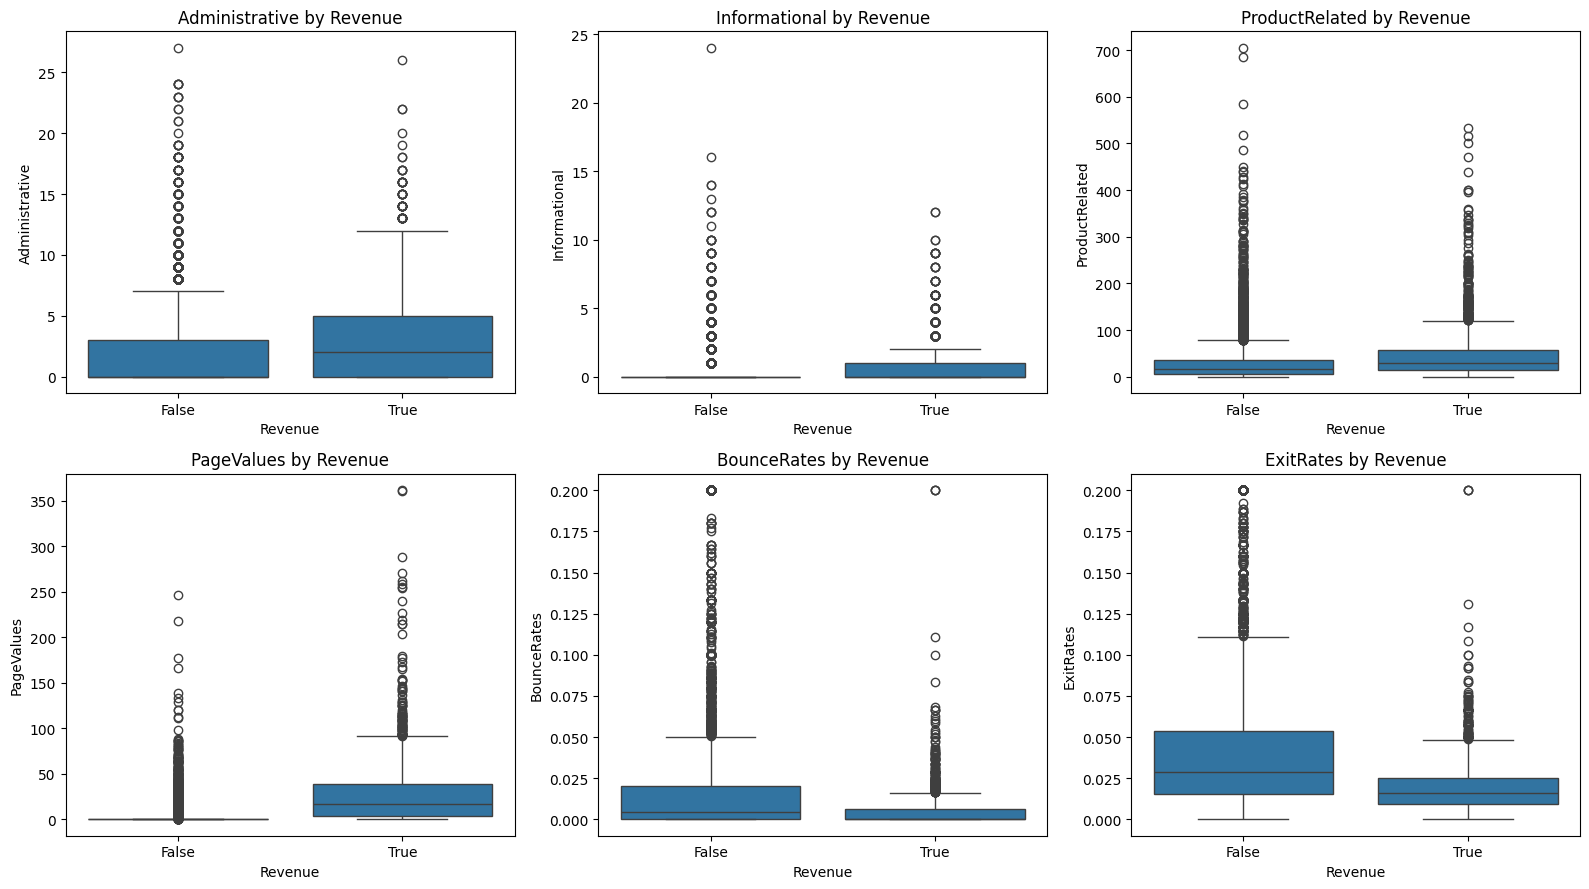

In [70]:
features_to_plot = [
    "Administrative",
    "Informational",
    "ProductRelated",
    "PageValues",
    "BounceRates",
    "ExitRates"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for feature, ax in zip(features_to_plot, axes.flatten()):
    sns.boxplot(data=df, x="Revenue", y=feature, ax=ax)
    ax.set_title(f"{feature} by Revenue")

plt.tight_layout()
plt.show()

Revenue            False  True 
VisitorType                    
New_Visitor        75.09  24.91
Other              81.18  18.82
Returning_Visitor  86.07  13.93


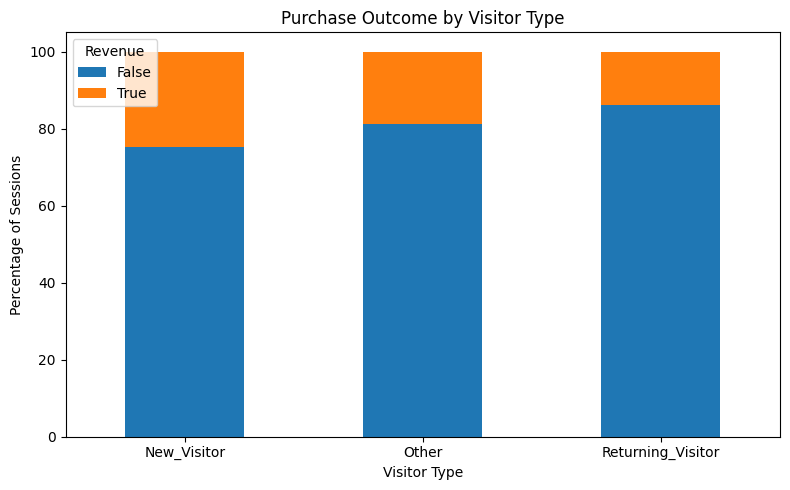

In [71]:
visitor_purchase = pd.crosstab(
    df["VisitorType"],
    df["Revenue"],
    normalize="index"
) * 100

print(visitor_purchase.round(2))

visitor_purchase.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Purchase Outcome by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Percentage of Sessions")
plt.legend(title="Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [72]:
# Display the first few duplicate rows
duplicate_rows = df[df.duplicated(keep=False)]

print("Rows involved in duplication:", len(duplicate_rows))
display(duplicate_rows.head(10))

# Check how many rows remain after removing duplicates
df_no_duplicates = df.drop_duplicates()

print("Original dataset shape:", df.shape)
print("Shape after removing duplicates:", df_no_duplicates.shape)

Rows involved in duplication: 201


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
85,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
132,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
252,0,0.0,0,0.0,2,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,False,False
286,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,1,1,Returning_Visitor,False,False
293,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,True,False
298,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,8,1,Returning_Visitor,False,False
330,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,3,2,3,1,Returning_Visitor,False,False


Original dataset shape: (12330, 18)
Shape after removing duplicates: (12205, 18)


In [73]:
# Remove exact duplicate rows
df_clean = df.drop_duplicates().copy()

print("Original dataset shape:", df.shape)
print("Dataset shape after removing duplicates:", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))

# Save the cleaned dataset to Google Drive
cleaned_path = os.path.join(DATA_DIR, "online_shoppers_cleaned.csv")
df_clean.to_csv(cleaned_path, index=False)

print("Cleaned dataset saved to:", cleaned_path)

Original dataset shape: (12330, 18)
Dataset shape after removing duplicates: (12205, 18)
Rows removed: 125
Cleaned dataset saved to: /content/drive/MyDrive/Online_Shoppers_ML/data/online_shoppers_cleaned.csv


In [74]:
# Summary statistics for numerical features
numerical_cols = df_clean.select_dtypes(include=["number"]).columns.tolist()

display(df_clean[numerical_cols].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Administrative,12205.0,2.34,3.33,0.0,0.00,1.00,4.00,27.00
Administrative_Duration,12205.0,81.65,177.49,0.0,0.00,9.00,94.70,3398.75
Informational,12205.0,0.51,1.28,0.0,0.00,0.00,0.00,24.00
Informational_Duration,12205.0,34.83,141.42,0.0,0.00,0.00,0.00,2549.38
ProductRelated,12205.0,32.05,44.59,0.0,8.00,18.00,38.00,705.00
ProductRelated_Duration,12205.0,1206.98,1919.60,0.0,193.00,608.94,1477.15,63973.52
BounceRates,12205.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20
ExitRates,12205.0,0.04,0.05,0.0,0.01,0.02,0.05,0.20
PageValues,12205.0,5.95,18.65,0.0,0.00,0.00,0.00,361.76
SpecialDay,12205.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00


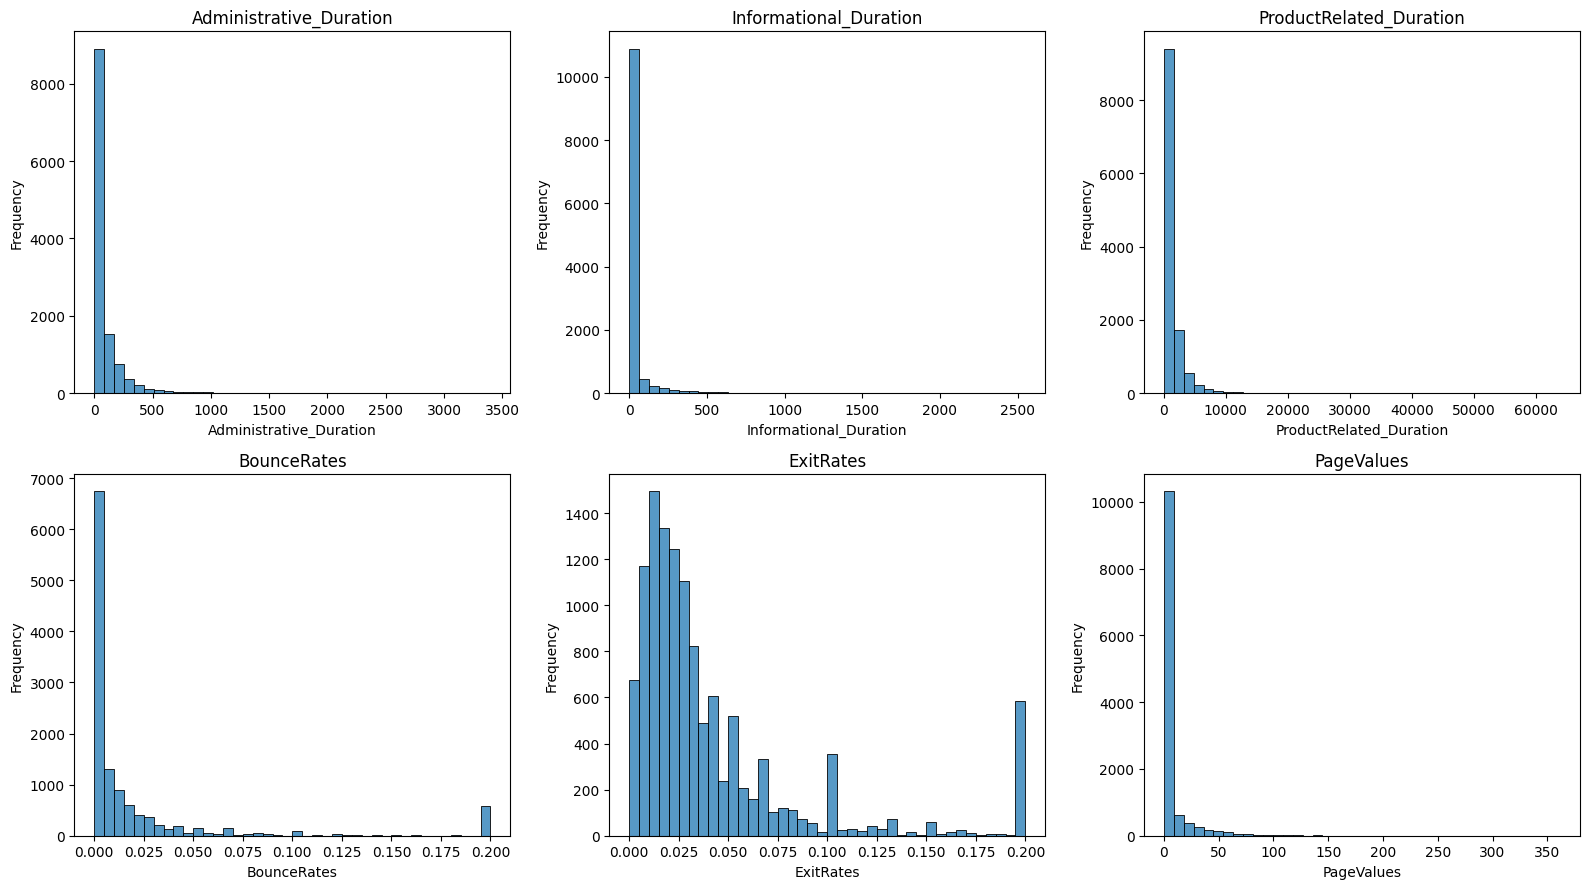

In [75]:
# Visualise numerical feature distributions
features_to_plot = [
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for feature, ax in zip(features_to_plot, axes.flatten()):
    sns.histplot(data=df_clean, x=feature, bins=40, ax=ax)
    ax.set_title(feature)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [76]:
# Purchase rate by categorical feature
categorical_features = [
    "Month",
    "VisitorType",
    "Weekend",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType"
]

for feature in categorical_features:
    purchase_rate = (
        df_clean.groupby(feature, observed=False)["Revenue"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    print(f"\nPurchase rate by {feature} (%):")
    display(purchase_rate.round(2).to_frame("Purchase Rate (%)"))


Purchase rate by Month (%):


,Purchase Rate (%)
Month,
Nov,25.49
Oct,20.95
Sep,19.20
Aug,17.55
Jul,15.28
Dec,12.66
May,10.96
Mar,10.32
June,10.18



Purchase rate by VisitorType (%):


,Purchase Rate (%)
VisitorType,
New_Visitor,24.93
Other,19.75
Returning_Visitor,14.09



Purchase rate by Weekend (%):


...

,Purchase Rate (%)
Browser,
12,30.00
13,28.57
10,19.63
5,18.49
4,17.78
11,16.67
8,15.56
2,15.51
1,15.04



Purchase rate by Region (%):


,Purchase Rate (%)
Region,
9,17.03
2,16.67
1,16.36
5,16.35
7,15.70
4,14.94
3,14.67
6,13.98
8,12.99



Purchase rate by TrafficType (%):


,Purchase Rate (%)
TrafficType,
16,33.33
7,30.00
8,27.70
20,25.91
2,21.66
5,21.54
10,20.00
11,19.03
4,15.48


,Count,Percentage (%)
Revenue,,
False,10297,84.37
True,1908,15.63


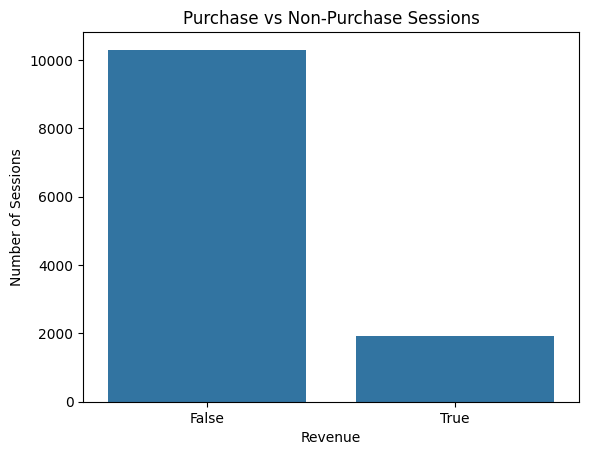

In [77]:
# Target distribution after duplicate removal
target_counts = df_clean["Revenue"].value_counts()
target_percentages = (
    df_clean["Revenue"].value_counts(normalize=True) * 100
)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_percentages.round(2)
})

display(target_summary)

sns.countplot(data=df_clean, x="Revenue")
plt.title("Purchase vs Non-Purchase Sessions")
plt.xlabel("Revenue")
plt.ylabel("Number of Sessions")
plt.show()

In [78]:
from sklearn.model_selection import train_test_split

# Separate predictors and target
X = df_clean.drop(columns=["Revenue"])
y = df_clean["Revenue"].astype(int)

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training features: (9764, 17)
Testing features: (2441, 17)

Training target distribution:
Revenue
0    84.37
1    15.63
Name: proportion, dtype: float64

Testing target distribution:
Revenue
0    84.35
1    15.65
Name: proportion, dtype: float64


In [79]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_cols
        )
    ]
)

print("Categorical features:", categorical_cols)
print("Numerical features:", numerical_cols)
print("Preprocessing setup completed.")

Categorical features: ['Month', 'VisitorType', 'Weekend']
Numerical features: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
Preprocessing setup completed.


In [80]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Define baseline models
baseline_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    )
}

# Train and evaluate baseline models
baseline_results = []
baseline_pipelines = {}

for name, model in baseline_models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    baseline_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    baseline_pipelines[name] = pipeline

    print(f"\n{'=' * 55}")
    print(name)
    print("=" * 55)
    print(classification_report(
        y_test,
        y_pred,
        target_names=["No Purchase", "Purchase"],
        zero_division=0
    ))
    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred))

# Display overall comparison
baseline_results_df = pd.DataFrame(baseline_results)
baseline_results_df = baseline_results_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

display(baseline_results_df.round(4))


Logistic Regression
              precision    recall  f1-score   support

 No Purchase       0.90      0.98      0.94      2059
    Purchase       0.77      0.42      0.54       382

    accuracy                           0.89      2441
   macro avg       0.84      0.70      0.74      2441
weighted avg       0.88      0.89      0.88      2441

Confusion matrix:
[[2012   47]
 [ 223  159]]

Random Forest
              precision    recall  f1-score   support

 No Purchase       0.92      0.96      0.94      2059
    Purchase       0.74      0.58      0.65       382

    accuracy                           0.90      2441
   macro avg       0.83      0.77      0.80      2441
weighted avg       0.90      0.90      0.90      2441

Confusion matrix:
[[1983   76]
 [ 162  220]]

Gradient Boosting
              precision    recall  f1-score   support

 No Purchase       0.93      0.96      0.94      2059
    Purchase       0.73      0.64      0.68       382

    accuracy                         

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Gradient Boosting,0.9054,0.7254,0.6361,0.6778,0.9363
1,Random Forest,0.9025,0.7432,0.5759,0.6490,0.9245
2,Logistic Regression,0.8894,0.7718,0.4162,0.5408,0.9022


In [81]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.base import clone
from scipy.stats import randint, uniform
import time

# Stratified cross-validation
cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Hyperparameter search spaces
param_distributions = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [None, 10, 20, 30],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", 0.8],
        "model__class_weight": [None, "balanced"]
    },

    "Gradient Boosting": {
        "model__n_estimators": [100, 150, 200],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [2, 3, 4],
        "model__min_samples_leaf": [1, 2, 5],
        "model__subsample": [0.8, 1.0]
    }
}

# Search for the best hyperparameters
tuned_searches = {}
tuning_summary = []

for name, model in baseline_models.items():
    print(f"\nTuning {name}...")

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", clone(model))
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions[name],
        n_iter=10,
        scoring="f1",
        cv=cv_strategy,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1,
        refit=True
    )

    start_time = time.time()
    search.fit(X_train, y_train)
    elapsed = time.time() - start_time

    tuned_searches[name] = search

    tuning_summary.append({
        "Model": name,
        "Best CV F1-score": search.best_score_,
        "Tuning Time (seconds)": round(elapsed, 2),
        "Best Parameters": search.best_params_
    })

    print("Best cross-validation F1-score:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)

tuning_summary_df = pd.DataFrame(tuning_summary)
display(tuning_summary_df)


Tuning Logistic Regression...
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best cross-validation F1-score: 0.6175
Best parameters: {'model__class_weight': 'balanced', 'model__C': 0.01}

Tuning Random Forest...
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best cross-validation F1-score: 0.6828
Best parameters: {'model__n_estimators': 300, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 30, 'model__class_weight': 'balanced'}

Tuning Gradient Boosting...
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best cross-validation F1-score: 0.663
Best parameters: {'model__subsample': 0.8, 'model__n_estimators': 200, 'model__min_samples_leaf': 2, 'model__max_depth': 4, 'model__learning_rate': 0.05}


,Model,Best CV F1-score,Tuning Time (seconds),Best Parameters
0,Logistic Regression,0.617500,5.37,"{'model__class_weight': 'balanced', 'model__C'..."
1,Random Forest,0.682812,98.60,"{'model__n_estimators': 300, 'model__min_sampl..."
2,Gradient Boosting,0.663017,90.76,"{'model__subsample': 0.8, 'model__n_estimators..."


In [82]:
tuned_results = []
tuned_pipelines = {}

for name, search in tuned_searches.items():
    best_model = search.best_estimator_
    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]

    tuned_pipelines[name] = best_model

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print(f"\n{'=' * 55}")
    print(f"Tuned {name}")
    print("=" * 55)
    print(classification_report(
        y_test,
        y_pred,
        target_names=["No Purchase", "Purchase"],
        zero_division=0
    ))
    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred))

tuned_results_df = pd.DataFrame(tuned_results).sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

print("\nTuned Model Comparison")
display(tuned_results_df.round(4))

# Compare baseline and tuned results
comparison_df = pd.concat([
    baseline_results_df.assign(Stage="Baseline"),
    tuned_results_df.assign(Stage="Tuned")
], ignore_index=True)

display(
    comparison_df[
        ["Model", "Stage", "Accuracy", "Precision",
         "Recall", "F1-score", "ROC-AUC"]
    ].sort_values(["Model", "Stage"])
    .round(4)
)


Tuned Logistic Regression
              precision    recall  f1-score   support

 No Purchase       0.95      0.88      0.91      2059
    Purchase       0.54      0.78      0.63       382

    accuracy                           0.86      2441
   macro avg       0.75      0.83      0.77      2441
weighted avg       0.89      0.86      0.87      2441

Confusion matrix:
[[1802  257]
 [  85  297]]

Tuned Random Forest
              precision    recall  f1-score   support

 No Purchase       0.94      0.94      0.94      2059
    Purchase       0.68      0.68      0.68       382

    accuracy                           0.90      2441
   macro avg       0.81      0.81      0.81      2441
weighted avg       0.90      0.90      0.90      2441

Confusion matrix:
[[1937  122]
 [ 124  258]]

Tuned Gradient Boosting
              precision    recall  f1-score   support

 No Purchase       0.93      0.96      0.94      2059
    Purchase       0.73      0.63      0.67       382

    accuracy       

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest,0.8992,0.6789,0.6754,0.6772,0.9310
1,Gradient Boosting,0.9045,0.7251,0.6283,0.6732,0.9364
2,Logistic Regression,0.8599,0.5361,0.7775,0.6346,0.9097


,Model,Stage,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Gradient Boosting,Baseline,0.9054,0.7254,0.6361,0.6778,0.9363
4,Gradient Boosting,Tuned,0.9045,0.7251,0.6283,0.6732,0.9364
2,Logistic Regression,Baseline,0.8894,0.7718,0.4162,0.5408,0.9022
5,Logistic Regression,Tuned,0.8599,0.5361,0.7775,0.6346,0.9097
1,Random Forest,Baseline,0.9025,0.7432,0.5759,0.6490,0.9245
3,Random Forest,Tuned,0.8992,0.6789,0.6754,0.6772,0.9310


In [83]:
from sklearn.ensemble import VotingClassifier
from sklearn.base import clone

# Combine the two selected tuned models
ensemble_model = VotingClassifier(
    estimators=[
        ("random_forest", clone(
            tuned_searches["Random Forest"].best_estimator_
        )),
        ("gradient_boosting", clone(
            tuned_searches["Gradient Boosting"].best_estimator_
        ))
    ],
    voting="soft",
    weights=[1, 1],
    n_jobs=-1
)

# Train the ensemble on the training data only
ensemble_model.fit(X_train, y_train)

# Evaluate on the untouched test data
ensemble_pred = ensemble_model.predict(X_test)
ensemble_prob = ensemble_model.predict_proba(X_test)[:, 1]

ensemble_metrics = {
    "Model": "Soft Voting Ensemble (RF + GB)",
    "Accuracy": accuracy_score(y_test, ensemble_pred),
    "Precision": precision_score(
        y_test, ensemble_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, ensemble_pred, zero_division=0
    ),
    "F1-score": f1_score(
        y_test, ensemble_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, ensemble_prob)
}

print("Soft Voting Ensemble (Random Forest + Gradient Boosting)")
print(classification_report(
    y_test,
    ensemble_pred,
    target_names=["No Purchase", "Purchase"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, ensemble_pred))

display(pd.DataFrame([ensemble_metrics]).round(4))

Soft Voting Ensemble (Random Forest + Gradient Boosting)
              precision    recall  f1-score   support

 No Purchase       0.94      0.95      0.94      2059
    Purchase       0.71      0.65      0.68       382

    accuracy                           0.90      2441
   macro avg       0.82      0.80      0.81      2441
weighted avg       0.90      0.90      0.90      2441

Confusion matrix:
[[1956  103]
 [ 132  250]]


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Soft Voting Ensemble (RF + GB),0.9037,0.7082,0.6545,0.6803,0.9348


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Soft Voting Ensemble (RF + GB),0.9037,0.7082,0.6545,0.6803,0.9348
1,Random Forest,0.8992,0.6789,0.6754,0.6772,0.9310
2,Gradient Boosting,0.9045,0.7251,0.6283,0.6732,0.9364
3,Logistic Regression,0.8599,0.5361,0.7775,0.6346,0.9097


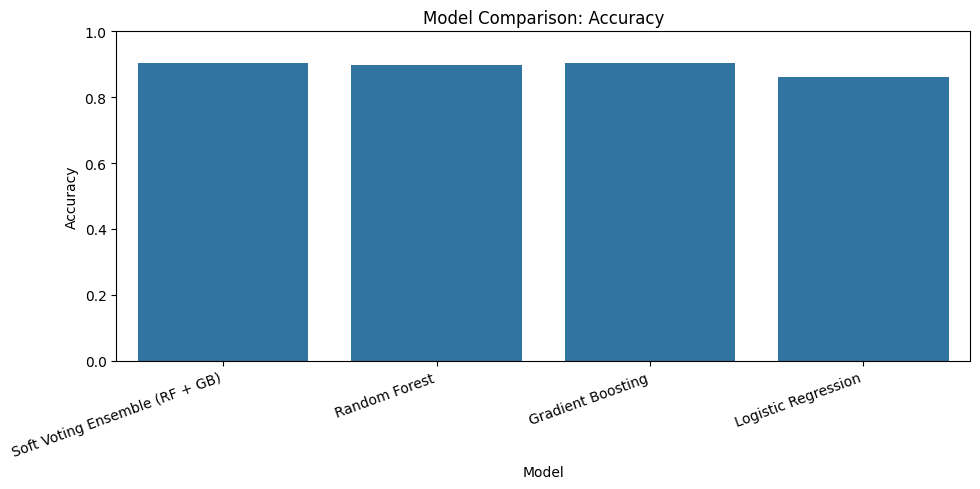

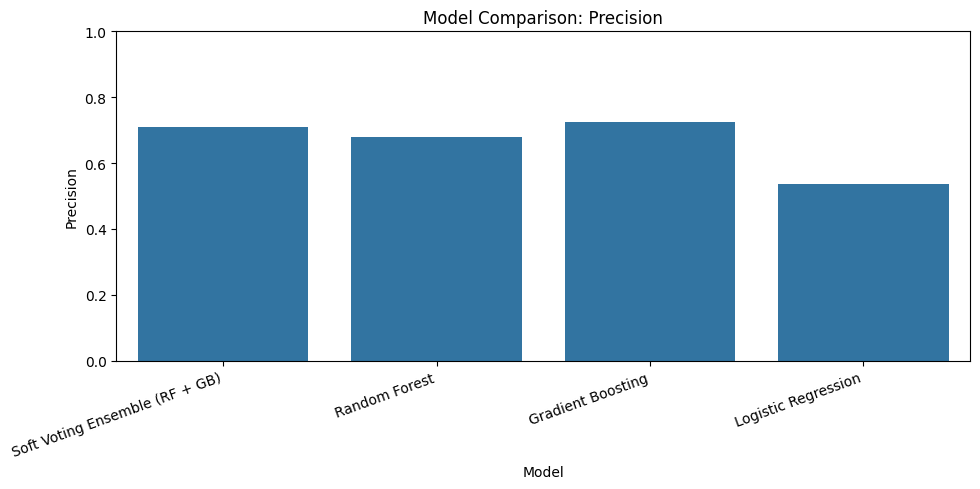

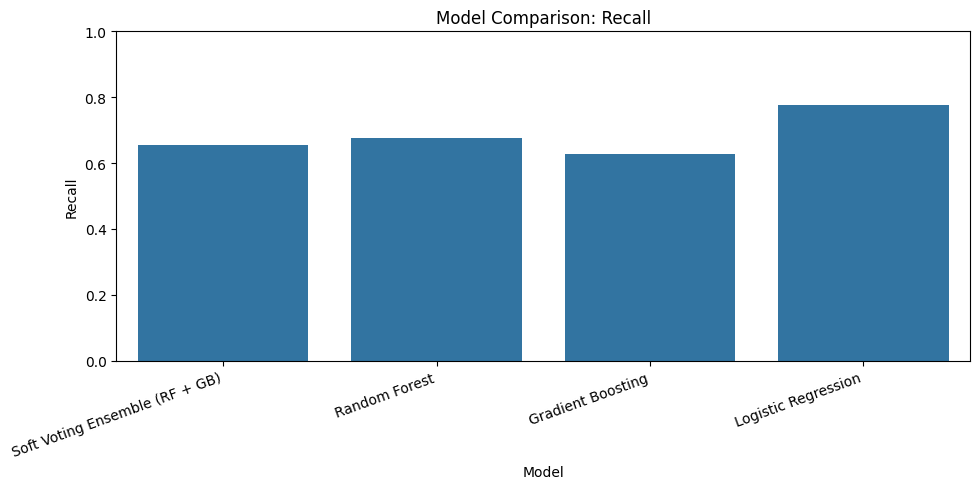

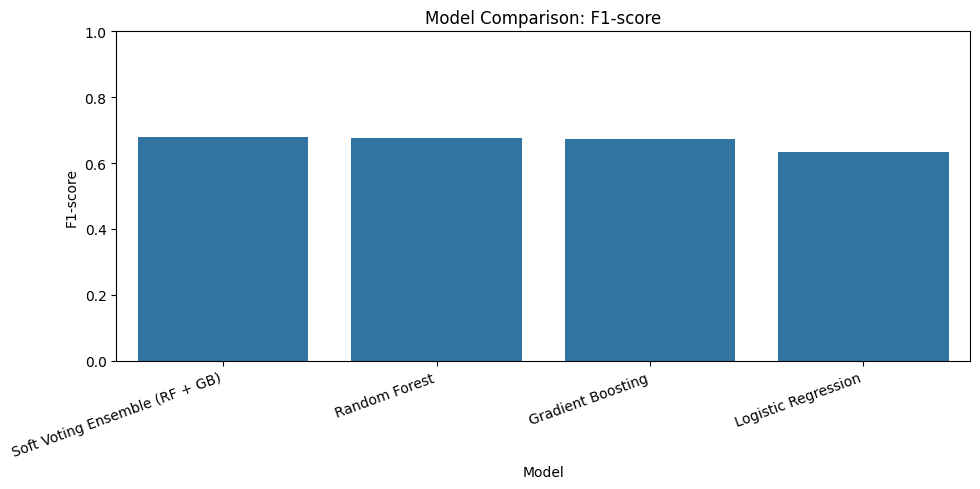

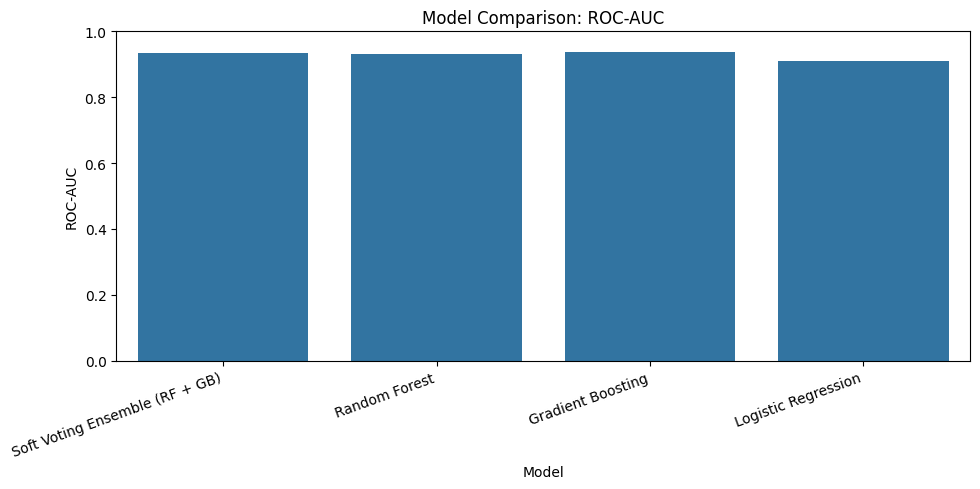

In [84]:
# Combine tuned model results and ensemble results
final_comparison_df = pd.concat(
    [
        tuned_results_df,
        pd.DataFrame([ensemble_metrics])
    ],
    ignore_index=True
)

final_comparison_df = final_comparison_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

display(final_comparison_df.round(4))

# Visual comparison of key metrics
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
]

for metric in metrics_to_plot:
    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=final_comparison_df,
        x="Model",
        y=metric
    )
    plt.title(f"Model Comparison: {metric}")
    plt.xticks(rotation=20, ha="right")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

Pearson Correlation with Revenue:
PageValues                 0.492
ExitRates                 -0.204
ProductRelated             0.156
ProductRelated_Duration    0.150
BounceRates               -0.145
Administrative             0.136
Informational              0.094
Administrative_Duration    0.092
SpecialDay                -0.084
Informational_Duration     0.069
Browser                    0.024
OperatingSystems          -0.015
Region                    -0.013
TrafficType               -0.006
Name: Revenue, dtype: float64


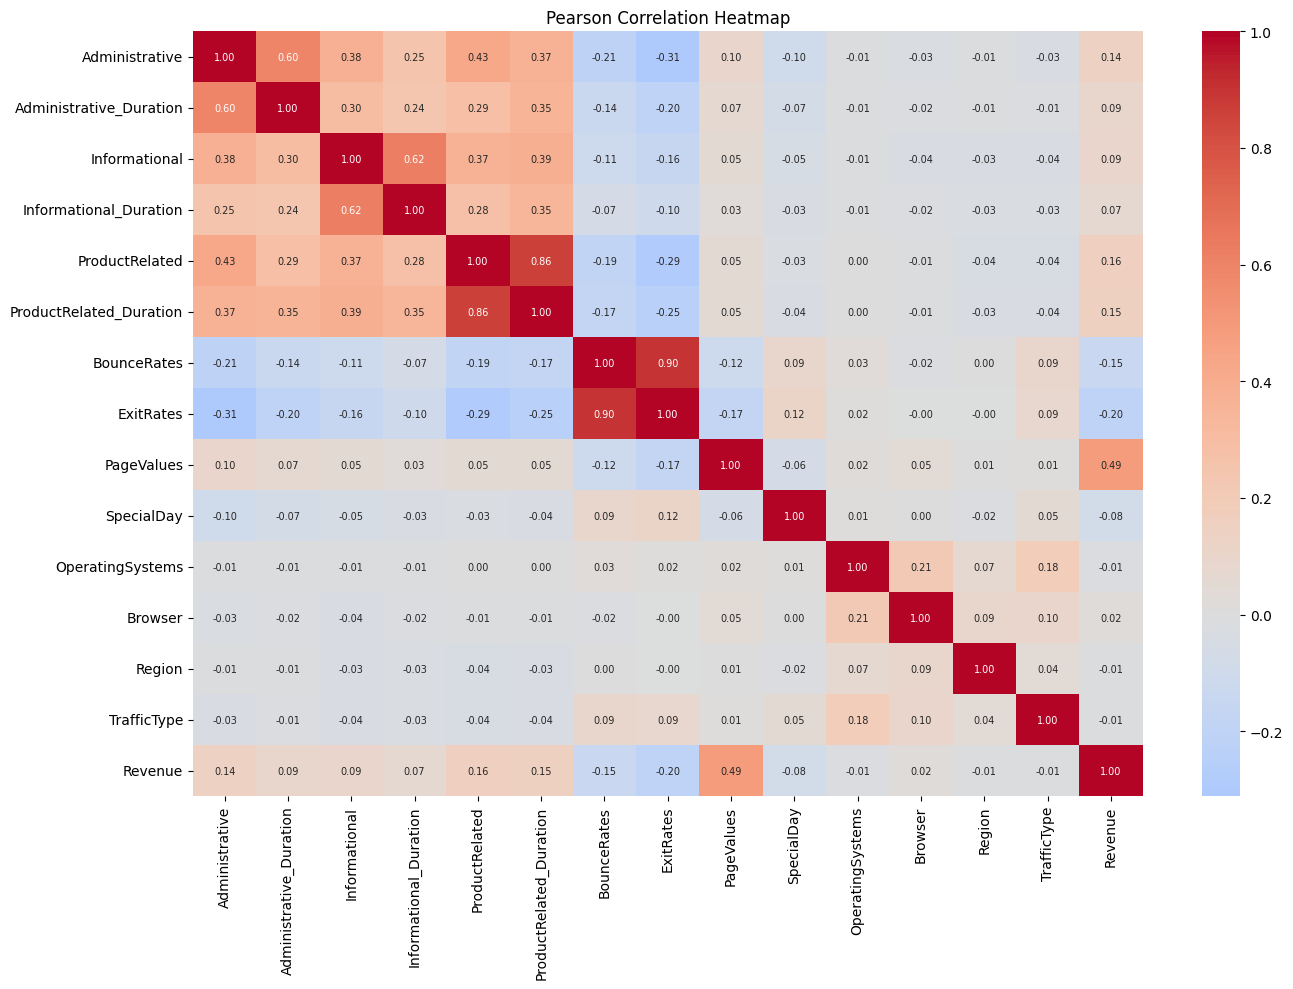

In [85]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert Revenue from Boolean to numeric if necessary
df_corr = df_clean.copy()
df_corr["Revenue"] = df_corr["Revenue"].astype(int)

# Calculate Pearson correlation coefficients
correlation_matrix = df_corr.select_dtypes(
    include="number"
).corr(method="pearson")

# Display correlations with Revenue, sorted by strength
revenue_corr = correlation_matrix["Revenue"].drop("Revenue")
revenue_corr = revenue_corr.reindex(
    revenue_corr.abs().sort_values(ascending=False).index
)

print("Pearson Correlation with Revenue:")
print(revenue_corr.round(3))

# Plot correlation heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    annot_kws={"size": 7}
)
plt.title("Pearson Correlation Heatmap")
plt.tight_layout()
plt.show()

In [86]:
# Select numerical features, excluding the target variable
numeric_features = df_clean.select_dtypes(
    include="number"
).drop(columns=["Revenue"], errors="ignore").columns

outlier_results = []

for feature in numeric_features:
    Q1 = df_clean[feature].quantile(0.25)
    Q3 = df_clean[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (df_clean[feature] < lower_bound) |
        (df_clean[feature] > upper_bound)
    )

    outlier_count = outlier_mask.sum()
    outlier_percentage = (
        outlier_count / len(df_clean)
    ) * 100

    outlier_results.append({
        "Feature": feature,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count,
        "Outlier Percentage (%)": outlier_percentage
    })

outlier_df = pd.DataFrame(outlier_results)

# Show features with the highest outlier percentages
outlier_df = outlier_df.sort_values(
    by="Outlier Percentage (%)",
    ascending=False
)

print(outlier_df.round(2).to_string(index=False))

                Feature  Lower Bound  Upper Bound  Outlier Count  Outlier Percentage (%)
                Browser         2.00         2.00           4322                   35.41
             PageValues         0.00         0.00           2730                   22.37
          Informational         0.00         0.00           2631                   21.56
 Informational_Duration         0.00         0.00           2405                   19.71
            TrafficType        -1.00         7.00           2084                   17.07
            BounceRates        -0.03         0.04           1428                   11.70
              ExitRates        -0.04         0.10           1325                   10.86
             SpecialDay         0.00         0.00           1249                   10.23
Administrative_Duration      -142.05       236.75           1149                    9.41
         ProductRelated       -37.00        83.00           1007                    8.25
ProductRelated_Durati

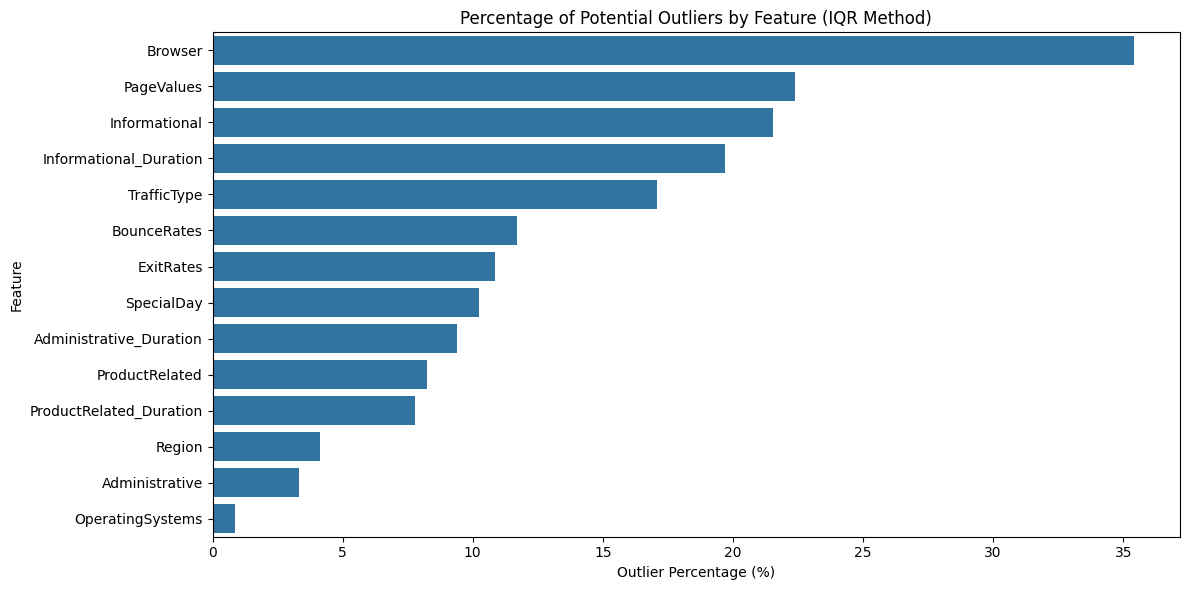

In [87]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=outlier_df,
    x="Outlier Percentage (%)",
    y="Feature"
)

plt.title("Percentage of Potential Outliers by Feature (IQR Method)")
plt.xlabel("Outlier Percentage (%)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

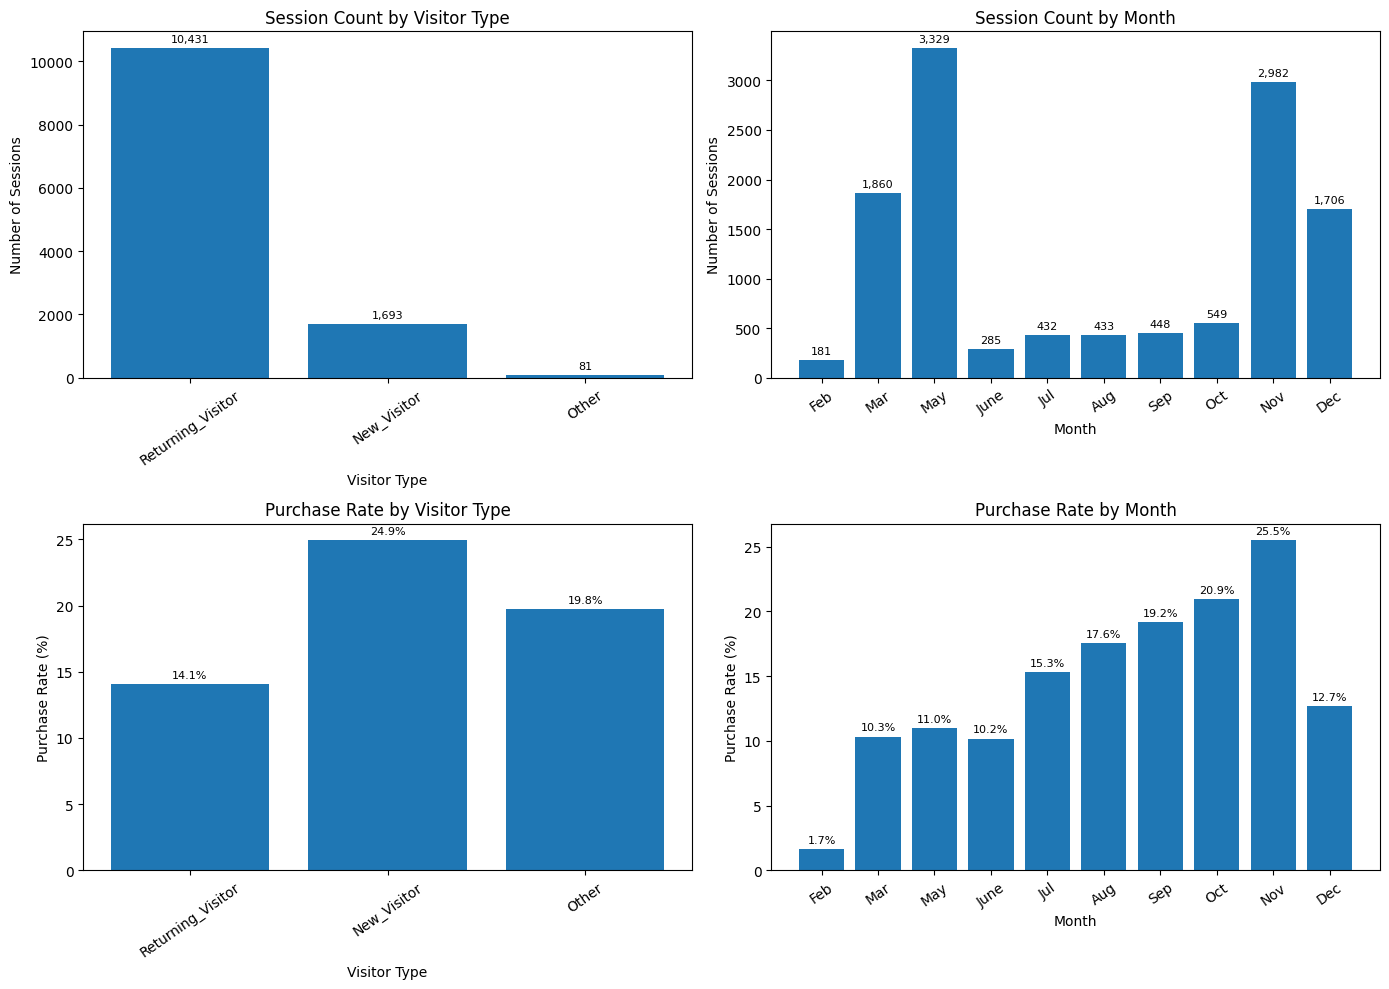

Session counts by visitor type:
VisitorType
Returning_Visitor    10431
New_Visitor           1693
Other                   81
Name: count, dtype: int64

Purchase rates by visitor type (%):
VisitorType
Returning_Visitor    14.09
New_Visitor          24.93
Other                19.75
Name: Revenue, dtype: float64

Session counts by month:
Month
Feb      181
Mar     1860
May     3329
June     285
Jul      432
Aug      433
Sep      448
Oct      549
Nov     2982
Dec     1706
Name: count, dtype: int64

Purchase rates by month (%):
Month
Feb      1.66
Mar     10.32
May     10.96
June    10.18
Jul     15.28
Aug     17.55
Sep     19.20
Oct     20.95
Nov     25.49
Dec     12.66
Name: Revenue, dtype: float64


In [88]:
import pandas as pd
import matplotlib.pyplot as plt

# Prepare data
df_plot = df_clean.copy()
df_plot["Revenue"] = df_plot["Revenue"].astype(int)

# Set category order
visitor_order = df_plot["VisitorType"].value_counts().index.tolist()

month_order = [
    "Feb", "Mar", "May", "June", "Jul",
    "Aug", "Sep", "Oct", "Nov", "Dec"
]
month_order = [
    month for month in month_order
    if month in df_plot["Month"].unique()
]

# Calculate session counts
visitor_counts = df_plot["VisitorType"].value_counts().reindex(
    visitor_order
)
month_counts = df_plot["Month"].value_counts().reindex(
    month_order
)

# Calculate purchase rates as percentages
visitor_purchase_rate = (
    df_plot.groupby("VisitorType")["Revenue"].mean() * 100
).reindex(visitor_order)

month_purchase_rate = (
    df_plot.groupby("Month")["Revenue"].mean() * 100
).reindex(month_order)

# Plot four charts
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

charts = [
    (axes[0, 0], visitor_counts, "Session Count by Visitor Type",
     "Visitor Type", "Number of Sessions"),
    (axes[0, 1], month_counts, "Session Count by Month",
     "Month", "Number of Sessions"),
    (axes[1, 0], visitor_purchase_rate, "Purchase Rate by Visitor Type",
     "Visitor Type", "Purchase Rate (%)"),
    (axes[1, 1], month_purchase_rate, "Purchase Rate by Month",
     "Month", "Purchase Rate (%)")
]

for ax, values, title, xlabel, ylabel in charts:
    bars = ax.bar(values.index.astype(str), values.values)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=35)

    # Display values above bars
    labels = [
        f"{v:.1f}%" if "Rate" in title else f"{v:,.0f}"
        for v in values.values
    ]
    ax.bar_label(bars, labels=labels, padding=3, fontsize=8)

plt.tight_layout()
plt.show()

# Print exact values for report interpretation
print("Session counts by visitor type:")
print(visitor_counts)

print("\nPurchase rates by visitor type (%):")
print(visitor_purchase_rate.round(2))

print("\nSession counts by month:")
print(month_counts)

print("\nPurchase rates by month (%):")
print(month_purchase_rate.round(2))

In [89]:
import os
import joblib
import json
from sklearn.metrics import classification_report, confusion_matrix

# Create folder for final model artefacts
MODEL_DIR = os.path.join(RESULTS_DIR, "final_model")
os.makedirs(MODEL_DIR, exist_ok=True)

# Save the trained models
joblib.dump(
    ensemble_model,
    os.path.join(MODEL_DIR, "soft_voting_ensemble.joblib")
)

joblib.dump(
    tuned_pipelines["Random Forest"],
    os.path.join(MODEL_DIR, "tuned_random_forest.joblib")
)

# Save model comparison results
final_comparison_df.to_csv(
    os.path.join(RESULTS_DIR, "final_model_comparison.csv"),
    index=False
)

baseline_results_df.to_csv(
    os.path.join(RESULTS_DIR, "baseline_results.csv"),
    index=False
)

tuned_results_df.to_csv(
    os.path.join(RESULTS_DIR, "tuned_model_results.csv"),
    index=False
)

# Save ensemble classification report
report = classification_report(
    y_test,
    ensemble_pred,
    target_names=["No Purchase", "Purchase"],
    output_dict=True,
    zero_division=0
)

with open(
    os.path.join(RESULTS_DIR, "ensemble_classification_report.json"),
    "w"
) as f:
    json.dump(report, f, indent=4)

# Save confusion matrix
cm = confusion_matrix(y_test, ensemble_pred)

pd.DataFrame(
    cm,
    index=["Actual No Purchase", "Actual Purchase"],
    columns=["Predicted No Purchase", "Predicted Purchase"]
).to_csv(os.path.join(RESULTS_DIR, "ensemble_confusion_matrix.csv"))

# Save predictions and predicted probabilities for analysis
prediction_results = pd.DataFrame({
    "Actual_Revenue": y_test.to_numpy(),
    "Predicted_Revenue": ensemble_pred,
    "Purchase_Probability": ensemble_prob
})

prediction_results.to_csv(
    os.path.join(RESULTS_DIR, "ensemble_test_predictions.csv"),
    index=False
)

print("Model and evaluation files saved successfully.")
print("Save location:", MODEL_DIR)
print("Results location:", RESULTS_DIR)

Model and evaluation files saved successfully.
Save location: /content/drive/MyDrive/Online_Shoppers_ML/results/final_model
Results location: /content/drive/MyDrive/Online_Shoppers_ML/results


In [90]:
for root, dirs, files in os.walk(RESULTS_DIR):
    for filename in sorted(files):
        print(os.path.join(root, filename))

/content/drive/MyDrive/Online_Shoppers_ML/results/baseline_results.csv
/content/drive/MyDrive/Online_Shoppers_ML/results/ensemble_classification_report.json
/content/drive/MyDrive/Online_Shoppers_ML/results/ensemble_confusion_matrix.csv
/content/drive/MyDrive/Online_Shoppers_ML/results/ensemble_test_predictions.csv
/content/drive/MyDrive/Online_Shoppers_ML/results/final_model_comparison.csv
/content/drive/MyDrive/Online_Shoppers_ML/results/tuned_model_results.csv
/content/drive/MyDrive/Online_Shoppers_ML/results/final_model/soft_voting_ensemble.joblib
/content/drive/MyDrive/Online_Shoppers_ML/results/final_model/tuned_random_forest.joblib
